In [1]:
import torch

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch Version: 2.14.1+cu130
GPU Available: True
GPU Name: Tesla T4


In [2]:
!pip install -q datasets tokenizers sacrebleu

import os
import re
import math
import random
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from datasets import load_dataset
import tokenizers
import sacrebleu

# Set global random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Configure visual styling for plots
sns.set_theme(style="whitegrid")

print("Libraries installed and imported successfully!")
print(f"datasets version   : {__import__('datasets').__version__}")
print(f"tokenizers version : {tokenizers.__version__}")
print(f"sacrebleu version  : {sacrebleu.__version__}")
print(f"pandas version     : {pd.__version__}")
print(f"numpy version      : {np.__version__}")

Libraries installed and imported successfully!
datasets version   : 4.8.5
tokenizers version : 0.23.3
sacrebleu version  : 2.6.0
pandas version     : 2.2.3
numpy version      : 2.4.6


In [3]:
# Load the fixed OPUS Books English-French dataset
dataset = load_dataset(
    "Helsinki-NLP/opus_books",
    "en-fr",
    split="train"
)

print("Dataset loaded successfully!")
print(f"Total records : {len(dataset):,}")
print(f"Column names  : {dataset.column_names}")
print(f"Features      : {dataset.features}\n")

# Display 5 sample English-French sentence pairs
print("--- Sample English-French Sentence Pairs ---")
for i in range(5):
    en_text = dataset[i]["translation"]["en"]
    fr_text = dataset[i]["translation"]["fr"]
    print(f"[{i}] EN: {en_text}")
    print(f"    FR: {fr_text}")
    print("-" * 60)

README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-fr/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

en-fr/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/127085 [00:00<?, ? examples/s]

Dataset loaded successfully!
Total records : 127,085
Column names  : ['id', 'translation']
Features      : {'id': Value('string'), 'translation': Translation(languages=['en', 'fr'])}

--- Sample English-French Sentence Pairs ---
[0] EN: The Wanderer
    FR: Le grand Meaulnes
------------------------------------------------------------
[1] EN: Alain-Fournier
    FR: Alain-Fournier
------------------------------------------------------------
[2] EN: First Part
    FR: PREMIÈRE PARTIE
------------------------------------------------------------
[3] EN: I
    FR: CHAPITRE PREMIER
------------------------------------------------------------
[4] EN: THE BOARDER
    FR: LE PENSIONNAIRE
------------------------------------------------------------


In [4]:
# Extract English and French texts into a Pandas DataFrame
df = pd.DataFrame({
    "en": [item["translation"]["en"] for item in dataset],
    "fr": [item["translation"]["fr"] for item in dataset]
})

print("--- Dataset Shape & Basic Info ---")
print(f"Total rows    : {len(df):,}")
print(f"Columns       : {list(df.columns)}\n")

print("--- Missing & Empty Value Analysis ---")
null_en = df["en"].isna().sum()
null_fr = df["fr"].isna().sum()
empty_en = (df["en"].astype(str).str.strip() == "").sum()
empty_fr = (df["fr"].astype(str).str.strip() == "").sum()

print(f"Null values   -> EN: {null_en} | FR: {null_fr}")
print(f"Empty strings -> EN: {empty_en} | FR: {empty_fr}\n")

print("--- Duplicate & Identity Analysis ---")
exact_pair_dups = df.duplicated(subset=["en", "fr"]).sum()
en_only_dups = df.duplicated(subset=["en"]).sum()
fr_only_dups = df.duplicated(subset=["fr"]).sum()
identical_en_fr = (df["en"].str.strip() == df["fr"].str.strip()).sum()

print(f"Exact (EN, FR) duplicate pairs : {exact_pair_dups:,}")
print(f"Duplicate English sentences    : {en_only_dups:,}")
print(f"Duplicate French sentences     : {fr_only_dups:,}")
print(f"Identical EN == FR strings     : {identical_en_fr:,}\n")

print("--- 5 Random Sentence Pairs from Corpus ---")
sample_df = df.sample(n=5, random_state=SEED)
for idx, row in sample_df.iterrows():
    print(f"[Row {idx}] EN: {row['en']}")
    print(f"           FR: {row['fr']}")
    print("-" * 60)

--- Dataset Shape & Basic Info ---
Total rows    : 127,085
Columns       : ['en', 'fr']

--- Missing & Empty Value Analysis ---
Null values   -> EN: 0 | FR: 0
Empty strings -> EN: 0 | FR: 0

--- Duplicate & Identity Analysis ---
Exact (EN, FR) duplicate pairs : 644
Duplicate English sentences    : 1,242
Duplicate French sentences     : 1,289
Identical EN == FR strings     : 92

--- 5 Random Sentence Pairs from Corpus ---
[Row 75823] EN: Le prince joua fort mal en effet ; on l’entendait à peine, et il ne savait plus terminer ses phrases.
           FR: The Prince did indeed act very badly; one could barely hear him, and he no longer knew how to end his sentences.
------------------------------------------------------------
[Row 88925] EN: Its shores seemed covered with greenery from its beaches to its summits inland, crowned by Mt. Kapogo, which is 476 fathoms high.
           FR: Les terres semblaient recouvertes de verdure depuis la plage jusqu'aux sommets de l'intérieur, que dominait

--- Word Length Summary Statistics ---
       en_word_len  fr_word_len  len_ratio
count    127085.00    127085.00  127085.00
mean         21.36        20.79       1.05
std          18.11        17.10       0.38
min           1.00         1.00       0.03
1%            2.00         2.00       0.50
5%            4.00         4.00       0.67
25%           9.00         9.00       0.90
50%          17.00        17.00       1.00
75%          28.00        27.00       1.15
90%          42.00        41.00       1.33
95%          54.00        52.00       1.50
99%          88.00        83.00       2.00
max         372.00       324.00      43.00

--- Sample Very Short Sentences (<= 2 words in EN) ---
EN (2w): The Wanderer  --->  FR (3w): Le grand Meaulnes
EN (1w): Alain-Fournier  --->  FR (1w): Alain-Fournier
EN (2w): First Part  --->  FR (2w): PREMIÈRE PARTIE
EN (1w): I  --->  FR (2w): CHAPITRE PREMIER
EN (2w): THE BOARDER  --->  FR (2w): LE PENSIONNAIRE

--- Sample Very Long Sentences (> 80 words

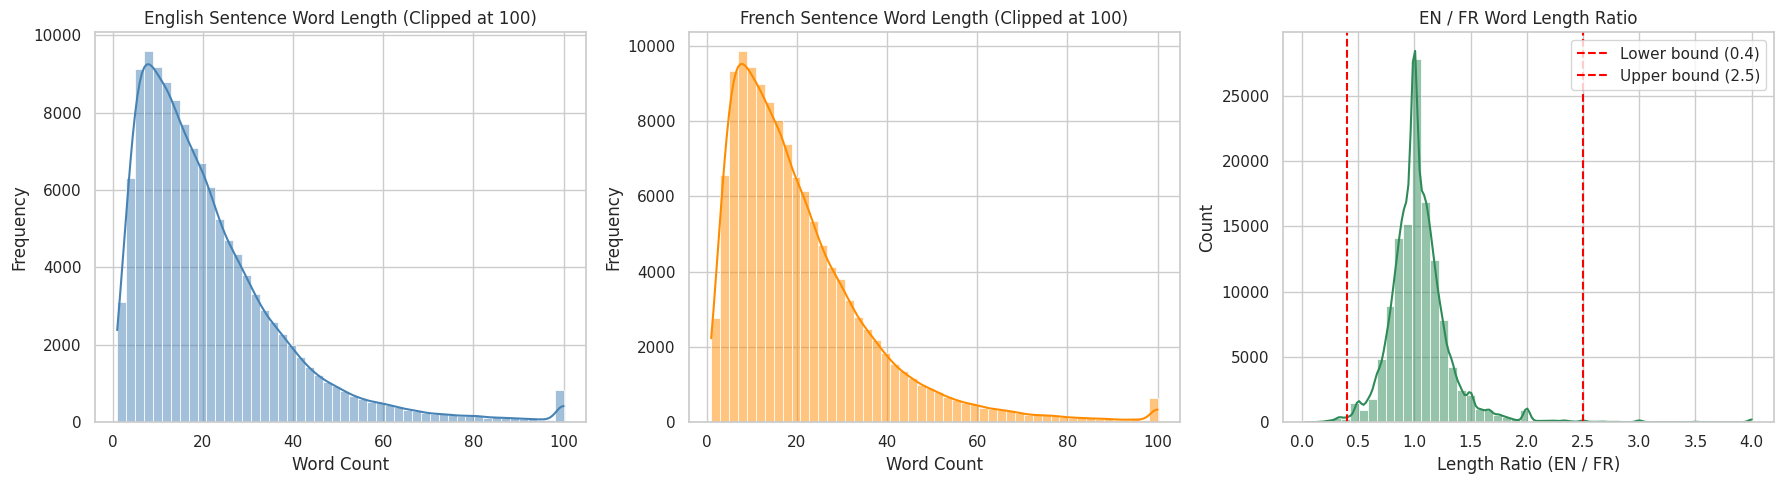

In [5]:
# Compute word counts and length ratios
df["en_word_len"] = df["en"].str.split().str.len()
df["fr_word_len"] = df["fr"].str.split().str.len()
df["len_ratio"] = df["en_word_len"] / df["fr_word_len"].replace(0, np.nan)

print("--- Word Length Summary Statistics ---")
stats = df[["en_word_len", "fr_word_len", "len_ratio"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)
print(stats.round(2))

# Inspect extreme outliers
print("\n--- Sample Very Short Sentences (<= 2 words in EN) ---")
for _, row in df[df["en_word_len"] <= 2].head(5).iterrows():
    print(f"EN ({row['en_word_len']}w): {row['en']}  --->  FR ({row['fr_word_len']}w): {row['fr']}")

print("\n--- Sample Very Long Sentences (> 80 words in EN) ---")
for _, row in df[df["en_word_len"] > 80].head(3).iterrows():
    print(f"EN ({row['en_word_len']}w): {row['en'][:120]}...")
    print(f"FR ({row['fr_word_len']}w): {row['fr'][:120]}...")
    print("-" * 50)

# Plot distributions using Matplotlib & Seaborn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. English word length distribution (clipped at 100 for readability)
sns.histplot(df["en_word_len"].clip(upper=100), bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("English Sentence Word Length (Clipped at 100)")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")

# 2. French word length distribution (clipped at 100 for readability)
sns.histplot(df["fr_word_len"].clip(upper=100), bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("French Sentence Word Length (Clipped at 100)")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Frequency")

# 3. Length ratio distribution (clipped at 4.0)
sns.histplot(df["len_ratio"].clip(upper=4.0), bins=50, kde=True, ax=axes[2], color="seagreen")
axes[2].axvline(0.4, color="red", linestyle="--", label="Lower bound (0.4)")
axes[2].axvline(2.5, color="red", linestyle="--", label="Upper bound (2.5)")
axes[2].set_title("EN / FR Word Length Ratio")
axes[2].set_xlabel("Length Ratio (EN / FR)")
axes[2].legend()

plt.tight_layout()
plt.savefig("phase2_sentence_length_distributions.png", dpi=150)
plt.show()

In [6]:
# Start from a clean copy of the raw DataFrame
clean_df = df[["en", "fr"]].copy()
audit_log = [("0. Initial raw dataset", len(clean_df))]

# Stage 1: Unicode normalization (NFKC) & whitespace cleanup (preserving French accents & punctuation)
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKC", str(text))
    # Remove non-printable control characters
    text = "".join(ch for ch in text if unicodedata.category(ch)[0] != "C")
    # Collapse multiple whitespace/tabs/newlines into a single space
    text = re.sub(r"\s+", " ", text).strip()
    return text

clean_df["en"] = clean_df["en"].apply(normalize_text)
clean_df["fr"] = clean_df["fr"].apply(normalize_text)

# Stage 2: Remove missing or empty records
clean_df = clean_df[(clean_df["en"] != "") & (clean_df["fr"] != "")].reset_index(drop=True)
audit_log.append(("1. After removing empty/null records", len(clean_df)))

# Stage 3: Remove exact (en, fr) duplicates and duplicate English sources
clean_df = clean_df.drop_duplicates(subset=["en", "fr"]).reset_index(drop=True)
audit_log.append(("2. After removing exact (EN, FR) duplicates", len(clean_df)))

clean_df = clean_df.drop_duplicates(subset=["en"]).reset_index(drop=True)
audit_log.append(("3. After removing duplicate EN source texts", len(clean_df)))

# Stage 4: Remove identical EN == FR strings (untranslated names/headers)
clean_df = clean_df[clean_df["en"].str.lower() != clean_df["fr"].str.lower()].reset_index(drop=True)
audit_log.append(("4. After removing identical EN == FR pairs", len(clean_df)))

# Stage 5: Detect and remove swapped EN/FR language rows
EN_MARKERS = {"the", "and", "of", "to", "in", "that", "was", "with", "for", "his", "her", "which"}
FR_MARKERS = {"le", "la", "les", "des", "du", "un", "une", "dans", "pour", "est", "qui", "que", "avec", "sur"}

def is_swapped_language(row) -> bool:
    en_tokens = set(re.findall(r"[a-zàâäéèêëîïôöùûüçœæ]+", row["en"].lower()))
    fr_tokens = set(re.findall(r"[a-zàâäéèêëîïôöùûüçœæ]+", row["fr"].lower()))

    # If the 'en' column has strong French markers & zero English markers, while 'fr' has strong English markers
    en_has_fr = len(en_tokens & FR_MARKERS) >= 2 and len(en_tokens & EN_MARKERS) == 0
    fr_has_en = len(fr_tokens & EN_MARKERS) >= 2 and len(fr_tokens & FR_MARKERS) == 0
    return en_has_fr and fr_has_en

swapped_mask = clean_df.apply(is_swapped_language, axis=1)
clean_df = clean_df[~swapped_mask].reset_index(drop=True)
audit_log.append(("5. After removing swapped EN/FR language rows", len(clean_df)))

# Stage 6: Filter sentence lengths (3 to 60 words) & alignment ratio (0.45 to 2.2)
en_lens = clean_df["en"].str.split().str.len()
fr_lens = clean_df["fr"].str.split().str.len()
ratios = en_lens / fr_lens

valid_length_mask = (
    (en_lens >= 3) & (en_lens <= 60) &
    (fr_lens >= 3) & (fr_lens <= 60) &
    (ratios >= 0.45) & (ratios <= 2.2)
)
clean_df = clean_df[valid_length_mask].reset_index(drop=True)
audit_log.append(("6. After length (3-60w) & ratio (0.45-2.2) filtering", len(clean_df)))

# Print complete audit table
print("--- Data Cleaning Audit Report ---")
prev_count = audit_log[0][1]
for stage, count in audit_log:
    removed = prev_count - count
    print(f"{stage:<55} | Remaining: {count:>7,} | Removed: {removed:>6,}")
    prev_count = count

total_removed = audit_log[0][1] - audit_log[-1][1]
print("-" * 92)
print(f"Total records removed: {total_removed:,} ({total_removed / audit_log[0][1] * 100:.2f}%)")
print(f"Final clean dataset  : {len(clean_df):,} pairs\n")

# Verify French accents and punctuation are preserved
print("--- Sample Cleaned Sentence Pairs (Verifying Accents & Punctuation) ---")
for i in range(5):
    print(f"[{i}] EN: {clean_df.loc[i, 'en']}")
    print(f"    FR: {clean_df.loc[i, 'fr']}")
    print("-" * 60)

--- Data Cleaning Audit Report ---
0. Initial raw dataset                                  | Remaining: 127,085 | Removed:      0
1. After removing empty/null records                    | Remaining: 127,085 | Removed:      0
2. After removing exact (EN, FR) duplicates             | Remaining: 126,440 | Removed:    645
3. After removing duplicate EN source texts             | Remaining: 125,843 | Removed:    597
4. After removing identical EN == FR pairs              | Remaining: 125,772 | Removed:     71
5. After removing swapped EN/FR language rows           | Remaining: 119,202 | Removed:  6,570
6. After length (3-60w) & ratio (0.45-2.2) filtering    | Remaining: 110,649 | Removed:  8,553
--------------------------------------------------------------------------------------------
Total records removed: 16,436 (12.93%)
Final clean dataset  : 110,649 pairs

--- Sample Cleaned Sentence Pairs (Verifying Accents & Punctuation) ---
[0] EN: He arrived at our home on a Sunday of November, 18

In [7]:
# Shuffle the cleaned DataFrame reproducibly using SEED = 42
shuffled_df = clean_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

total_records = len(shuffled_df)
train_end = int(0.80 * total_records)
val_end = int(0.90 * total_records)

train_df = shuffled_df.iloc[:train_end].reset_index(drop=True)
val_df = shuffled_df.iloc[train_end:val_end].reset_index(drop=True)
test_df = shuffled_df.iloc[val_end:].reset_index(drop=True)

print("--- Dataset Split Summary (80% / 10% / 10%) ---")
print(f"Total Clean Records : {total_records:,}")
print(f"Training Set (80%)  : {len(train_df):,} ({len(train_df)/total_records*100:.2f}%)")
print(f"Validation Set (10%): {len(val_df):,} ({len(val_df)/total_records*100:.2f}%)")
print(f"Test Set (10%)      : {len(test_df):,} ({len(test_df)/total_records*100:.2f}%)\n")

# Verify zero data leakage across splits
train_en_set = set(train_df["en"])
val_en_set = set(val_df["en"])
test_en_set = set(test_df["en"])

train_val_overlap = len(train_en_set & val_en_set)
train_test_overlap = len(train_en_set & test_en_set)
val_test_overlap = len(val_en_set & test_en_set)

print("--- Data Leakage Verification ---")
print(f"Train ∩ Validation overlap : {train_val_overlap}")
print(f"Train ∩ Test overlap       : {train_test_overlap}")
print(f"Validation ∩ Test overlap  : {val_test_overlap}")

assert train_val_overlap == 0 and train_test_overlap == 0 and val_test_overlap == 0, "Data leakage detected!"
print("SUCCESS: Zero data leakage confirmed across all three splits!")

--- Dataset Split Summary (80% / 10% / 10%) ---
Total Clean Records : 110,649
Training Set (80%)  : 88,519 (80.00%)
Validation Set (10%): 11,065 (10.00%)
Test Set (10%)      : 11,065 (10.00%)

--- Data Leakage Verification ---
Train ∩ Validation overlap : 0
Train ∩ Test overlap       : 0
Validation ∩ Test overlap  : 0
SUCCESS: Zero data leakage confirmed across all three splits!


In [8]:
from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers, processors

# Define special tokens and fixed IDs
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
BOS_TOKEN = "<bos>"
EOS_TOKEN = "<eos>"
SPECIAL_TOKENS = [PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN]

VOCAB_SIZE = 16000  # Optimal balance of coverage and embedding matrix size for T4 GPU

# Iterator yielding ONLY training English and French sentences (zero val/test leakage)
def train_corpus_iterator(batch_size: int = 1000):
    en_list = train_df["en"].tolist()
    fr_list = train_df["fr"].tolist()
    for i in range(0, len(en_list), batch_size):
        yield en_list[i : i + batch_size] + fr_list[i : i + batch_size]

# 1. Initialize a blank Byte-Pair Encoding (BPE) model
tokenizer = Tokenizer(models.BPE(unk_token=UNK_TOKEN))

# 2. ByteLevel pre-tokenizer preserves spaces, French accents, and punctuation losslessly
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()

# 3. Configure BPE trainer
trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=SPECIAL_TOKENS
)

# 4. Train tokenizer from scratch on train_df ONLY
tokenizer.train_from_iterator(train_corpus_iterator(), trainer=trainer)

# Retrieve exact special token IDs
PAD_IDX = tokenizer.token_to_id(PAD_TOKEN)
UNK_IDX = tokenizer.token_to_id(UNK_TOKEN)
BOS_IDX = tokenizer.token_to_id(BOS_TOKEN)
EOS_IDX = tokenizer.token_to_id(EOS_TOKEN)

# 5. Automatically wrap encoded sentences with <bos> ... <eos>
tokenizer.post_processor = processors.TemplateProcessing(
    single=f"{BOS_TOKEN} $A {EOS_TOKEN}",
    special_tokens=[(BOS_TOKEN, BOS_IDX), (EOS_TOKEN, EOS_IDX)],
)

# Save custom tokenizer to disk for reproducibility and Phase 10 deliverables
os.makedirs("artifacts", exist_ok=True)
tokenizer_path = "artifacts/custom_bpe_en_fr_tokenizer.json"
tokenizer.save(tokenizer_path)

print("Custom Shared BPE Tokenizer trained from scratch successfully!")
print(f"Saved to         : {tokenizer_path}")
print(f"Vocabulary Size  : {tokenizer.get_vocab_size():,}")
print(f"Special Token IDs: PAD={PAD_IDX}, UNK={UNK_IDX}, BOS={BOS_IDX}, EOS={EOS_IDX}\n")

# Test tokenization & round-trip decoding on sample English and French sentences
sample_en = "We left that part of the country nearly fifteen years ago."
sample_fr = "Nous avons quitté le pays depuis bientôt quinze ans."

enc_en = tokenizer.encode(sample_en)
enc_fr = tokenizer.encode(sample_fr)

print("--- Tokenization Verification ---")
print(f"Original EN : {sample_en}")
print(f"Tokens EN   : {enc_en.tokens}")
print(f"Token IDs EN: {enc_en.ids}")
print(f"Decoded EN  : {tokenizer.decode(enc_en.ids, skip_special_tokens=True)}\n")

print(f"Original FR : {sample_fr}")
print(f"Tokens FR   : {enc_fr.tokens}")
print(f"Token IDs FR: {enc_fr.ids}")
print(f"Decoded FR  : {tokenizer.decode(enc_fr.ids, skip_special_tokens=True)}")

Custom Shared BPE Tokenizer trained from scratch successfully!
Saved to         : artifacts/custom_bpe_en_fr_tokenizer.json
Vocabulary Size  : 16,000
Special Token IDs: PAD=0, UNK=1, BOS=2, EOS=3

--- Tokenization Verification ---
Original EN : We left that part of the country nearly fifteen years ago.
Tokens EN   : ['<bos>', 'We', 'Ġleft', 'Ġthat', 'Ġpart', 'Ġof', 'Ġthe', 'Ġcountry', 'Ġnearly', 'Ġfifteen', 'Ġyears', 'Ġago', '.', '<eos>']
Token IDs EN: [2, 1135, 1118, 254, 547, 188, 162, 2287, 3968, 5935, 1965, 4778, 17, 3]
Decoded EN  : We left that part of the country nearly fifteen years ago.

Original FR : Nous avons quitté le pays depuis bientôt quinze ans.
Tokens FR   : ['<bos>', 'Nous', 'Ġavons', 'ĠquittÃ©', 'Ġle', 'Ġpays', 'Ġdepuis', 'ĠbientÃ´t', 'Ġquinze', 'Ġans', '.', '<eos>']
Token IDs FR: [2, 1446, 3042, 5509, 193, 2129, 1448, 2115, 4179, 1000, 17, 3]
Decoded FR  : Nous avons quitté le pays depuis bientôt quinze ans.


In [9]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# 1. Analyze tokenized lengths on the training split to validate MAX_SEQ_LEN
en_token_lens = [len(tokenizer.encode(text).ids) for text in train_df["en"]]
fr_token_lens = [len(tokenizer.encode(text).ids) for text in train_df["fr"]]

print("--- Tokenized Sequence Length Distribution (Train Set) ---")
print(f"EN Tokens -> Mean: {np.mean(en_token_lens):.1f} | 95th%: {np.percentile(en_token_lens, 95):.0f} | 99th%: {np.percentile(en_token_lens, 99):.0f} | Max: {np.max(en_token_lens)}")
print(f"FR Tokens -> Mean: {np.mean(fr_token_lens):.1f} | 95th%: {np.percentile(fr_token_lens, 95):.0f} | 99th%: {np.percentile(fr_token_lens, 99):.0f} | Max: {np.max(fr_token_lens)}\n")

MAX_SEQ_LEN = 96
BATCH_SIZE = 64

# 2. Custom PyTorch Dataset class
class TranslationDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, bpe_tokenizer: Tokenizer, max_len: int = MAX_SEQ_LEN):
        self.src_sequences = []
        self.tgt_sequences = []

        for en_text, fr_text in zip(dataframe["en"], dataframe["fr"]):
            src_ids = bpe_tokenizer.encode(en_text).ids
            tgt_ids = bpe_tokenizer.encode(fr_text).ids

            # Truncate cleanly while guaranteeing <eos> remains at the end
            if len(src_ids) > max_len:
                src_ids = src_ids[: max_len - 1] + [EOS_IDX]
            if len(tgt_ids) > max_len:
                tgt_ids = tgt_ids[: max_len - 1] + [EOS_IDX]

            self.src_sequences.append(torch.tensor(src_ids, dtype=torch.long))
            self.tgt_sequences.append(torch.tensor(tgt_ids, dtype=torch.long))

    def __len__(self) -> int:
        return len(self.src_sequences)

    def __getitem__(self, idx: int):
        return self.src_sequences[idx], self.tgt_sequences[idx]

# 3. Dynamic padding collate function
def collate_batch(batch):
    src_list, tgt_list = zip(*batch)
    src_padded = pad_sequence(src_list, batch_first=True, padding_value=PAD_IDX)
    tgt_padded = pad_sequence(tgt_list, batch_first=True, padding_value=PAD_IDX)
    return src_padded, tgt_padded

# Instantiate Datasets and DataLoaders
train_dataset = TranslationDataset(train_df, tokenizer, MAX_SEQ_LEN)
val_dataset   = TranslationDataset(val_df, tokenizer, MAX_SEQ_LEN)
test_dataset  = TranslationDataset(test_df, tokenizer, MAX_SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch, pin_memory=True)

# 4. Verify batch tensor shapes
sample_src, sample_tgt = next(iter(train_loader))
print("--- PyTorch DataLoader Verification ---")
print(f"Train batches : {len(train_loader):,} | Val batches: {len(val_loader):,} | Test batches: {len(test_loader):,}")
print(f"Sample Batch Source Tensor Shape: {sample_src.shape} (Batch Size x Max Batch Src Len)")
print(f"Sample Batch Target Tensor Shape: {sample_tgt.shape} (Batch Size x Max Batch Tgt Len)")
print(f"Sample Source[0] First 10 IDs   : {sample_src[0][:10].tolist()}")
print(f"Sample Target[0] First 10 IDs   : {sample_tgt[0][:10].tolist()}")

--- Tokenized Sequence Length Distribution (Train Set) ---
EN Tokens -> Mean: 27.4 | 95th%: 59 | 99th%: 74 | Max: 201
FR Tokens -> Mean: 29.8 | 95th%: 65 | 99th%: 82 | Max: 204

--- PyTorch DataLoader Verification ---
Train batches : 1,384 | Val batches: 173 | Test batches: 173
Sample Batch Source Tensor Shape: torch.Size([64, 78]) (Batch Size x Max Batch Src Len)
Sample Batch Target Tensor Shape: torch.Size([64, 78]) (Batch Size x Max Batch Tgt Len)
Sample Source[0] First 10 IDs   : [2, 5, 42, 5166, 288, 15, 1732, 349, 3, 0]
Sample Target[0] First 10 IDs   : [2, 283, 762, 328, 193, 1169, 1248, 15, 442, 2142]


In [10]:
class TokenEmbedding(nn.Module):
    """Maps integer token IDs to dense d_model vectors scaled by sqrt(d_model)."""
    def __init__(self, vocab_size: int, d_model: int, pad_idx: int = 0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.d_model = d_model

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x shape: (batch_size, seq_len) -> output: (batch_size, seq_len, d_model)
        return self.embedding(x) * math.sqrt(self.d_model)


class PositionalEncoding(nn.Module):
    """Injects deterministic sinusoidal positional information into token embeddings."""
    def __init__(self, d_model: int, dropout: float = 0.1, max_len: int = 512):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # Shape: (1, max_len, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Add positional encoding slice matching input sequence length
        x = x + self.pe[:, : x.size(1), :]
        return self.dropout(x)


class MultiHeadAttention(nn.Module):
    """
    Explicit Multi-Head Scaled Dot-Product Attention built from scratch.
    Supports:
      - Encoder Self-Attention (query=key=value=src)
      - Decoder Masked Self-Attention (query=key=value=tgt, with causal + padding mask)
      - Decoder Cross-Attention (query=tgt, key=value=encoder_output)
    """
    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        # Linear projections for Q, K, V and final output
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(p=dropout)

    def scaled_dot_product_attention(
        self,
        q: torch.Tensor,
        k: torch.Tensor,
        v: torch.Tensor,
        mask: torch.Tensor = None
    ):
        # q, k, v shape: (batch_size, num_heads, seq_len, d_k)
        # Compute attention scores: (batch_size, num_heads, seq_len_q, seq_len_k)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)

        # Apply mask (1 = keep, 0 = mask out)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e4)

        attn_weights = torch.softmax(scores, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Weighted sum of values: (batch_size, num_heads, seq_len_q, d_k)
        context = torch.matmul(attn_weights, v)
        return context, attn_weights

    def forward(
        self,
        query: torch.Tensor,
        key: torch.Tensor,
        value: torch.Tensor,
        mask: torch.Tensor = None
    ):
        batch_size = query.size(0)

        # 1. Project Q, K, V and reshape to (batch_size, num_heads, seq_len, d_k)
        q = self.w_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        k = self.w_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        v = self.w_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # 2. Apply Scaled Dot-Product Attention
        context, attn_weights = self.scaled_dot_product_attention(q, k, v, mask=mask)

        # 3. Concatenate all heads back to (batch_size, seq_len_q, d_model)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)

        # 4. Final output linear projection
        output = self.w_o(context)
        return output, attn_weights


# Quick unit test on dummy tensors to verify shapes
dummy_x = torch.randint(0, VOCAB_SIZE, (4, 12))
emb_layer = TokenEmbedding(VOCAB_SIZE, d_model=256, pad_idx=PAD_IDX)
pos_layer = PositionalEncoding(d_model=256)
mha_layer = MultiHeadAttention(d_model=256, num_heads=8)

embedded = pos_layer(emb_layer(dummy_x))
attn_out, attn_probs = mha_layer(embedded, embedded, embedded)

print("Step 1 Transformer Building Blocks Verified!")
print(f"Embedded Shape         : {embedded.shape}  (expected: [4, 12, 256])")
print(f"MHA Output Shape       : {attn_out.shape}  (expected: [4, 12, 256])")
print(f"Attention Weights Shape: {attn_probs.shape} (expected: [4, 8, 12, 12])")

Step 1 Transformer Building Blocks Verified!
Embedded Shape         : torch.Size([4, 12, 256])  (expected: [4, 12, 256])
MHA Output Shape       : torch.Size([4, 12, 256])  (expected: [4, 12, 256])
Attention Weights Shape: torch.Size([4, 8, 12, 12]) (expected: [4, 8, 12, 12])


In [11]:
class PositionwiseFeedForward(nn.Module):
    """Two-layer position-wise MLP applied independently to every sequence token."""
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.activation = nn.GELU()
        self.dropout = nn.Dropout(p=dropout)
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear2(self.dropout(self.activation(self.linear1(x))))


class EncoderLayer(nn.Module):
    """Single Transformer Encoder block using Pre-LayerNorm + Residual Connections."""
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(p=dropout)
        self.dropout2 = nn.Dropout(p=dropout)

    def forward(self, src: torch.Tensor, src_mask: torch.Tensor = None) -> torch.Tensor:
        # 1. Pre-LN Multi-Head Self-Attention + Residual
        normed_src = self.norm1(src)
        attn_out, _ = self.self_attn(normed_src, normed_src, normed_src, mask=src_mask)
        src = src + self.dropout1(attn_out)

        # 2. Pre-LN Feed-Forward Network + Residual
        normed_src = self.norm2(src)
        ff_out = self.feed_forward(normed_src)
        src = src + self.dropout2(ff_out)
        return src


class DecoderLayer(nn.Module):
    """
    Single Transformer Decoder block with:
      1. Masked Self-Attention (causal + padding mask)
      2. Encoder-Decoder Cross-Attention (Q from decoder, K & V from encoder)
      3. Position-Wise Feed-Forward Network
    """
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

        self.dropout1 = nn.Dropout(p=dropout)
        self.dropout2 = nn.Dropout(p=dropout)
        self.dropout3 = nn.Dropout(p=dropout)

    def forward(
        self,
        tgt: torch.Tensor,
        enc_output: torch.Tensor,
        tgt_mask: torch.Tensor = None,
        src_mask: torch.Tensor = None
    ):
        # 1. Pre-LN Masked Self-Attention over target sequence
        normed_tgt = self.norm1(tgt)
        self_attn_out, _ = self.self_attn(normed_tgt, normed_tgt, normed_tgt, mask=tgt_mask)
        tgt = tgt + self.dropout1(self_attn_out)

        # 2. Pre-LN Cross-Attention (Query = French Decoder, Key/Value = English Encoder)
        normed_tgt = self.norm2(tgt)
        cross_attn_out, cross_attn_weights = self.cross_attn(
            query=normed_tgt,
            key=enc_output,
            value=enc_output,
            mask=src_mask
        )
        tgt = tgt + self.dropout2(cross_attn_out)

        # 3. Pre-LN Feed-Forward Network
        normed_tgt = self.norm3(tgt)
        ff_out = self.feed_forward(normed_tgt)
        tgt = tgt + self.dropout3(ff_out)

        return tgt, cross_attn_weights


# Unit test EncoderLayer and DecoderLayer tensor shapes
dummy_src_emb = torch.randn(4, 12, 256)
dummy_tgt_emb = torch.randn(4, 15, 256)

enc_layer = EncoderLayer(d_model=256, num_heads=8, d_ff=1024)
dec_layer = DecoderLayer(d_model=256, num_heads=8, d_ff=1024)

enc_out = enc_layer(dummy_src_emb)
dec_out, cross_probs = dec_layer(dummy_tgt_emb, enc_out)

print("Step 2 EncoderLayer & DecoderLayer Verified!")
print(f"EncoderLayer Output Shape    : {enc_out.shape}     (expected: [4, 12, 256])")
print(f"DecoderLayer Output Shape    : {dec_out.shape}     (expected: [4, 15, 256])")
print(f"Cross-Attention Weights Shape: {cross_probs.shape}  (expected: [4, 8, 15, 12])")

Step 2 EncoderLayer & DecoderLayer Verified!
EncoderLayer Output Shape    : torch.Size([4, 12, 256])     (expected: [4, 12, 256])
DecoderLayer Output Shape    : torch.Size([4, 15, 256])     (expected: [4, 15, 256])
Cross-Attention Weights Shape: torch.Size([4, 8, 15, 12])  (expected: [4, 8, 15, 12])


In [12]:
class Encoder(nn.Module):
    """Full Transformer Encoder stack."""
    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        num_layers: int,
        num_heads: int,
        d_ff: int,
        dropout: float = 0.1,
        pad_idx: int = 0,
        max_len: int = 512
    ):
        super().__init__()
        self.token_embedding = TokenEmbedding(vocab_size, d_model, pad_idx=pad_idx)
        self.pos_encoding = PositionalEncoding(d_model, dropout=dropout, max_len=max_len)
        self.layers = nn.ModuleList([
            EncoderLayer(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)

    def forward(self, src: torch.Tensor, src_mask: torch.Tensor) -> torch.Tensor:
        x = self.pos_encoding(self.token_embedding(src))
        for layer in self.layers:
            x = layer(x, src_mask)
        return self.final_norm(x)


class Decoder(nn.Module):
    """Full Transformer Decoder stack."""
    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        num_layers: int,
        num_heads: int,
        d_ff: int,
        dropout: float = 0.1,
        pad_idx: int = 0,
        max_len: int = 512
    ):
        super().__init__()
        self.token_embedding = TokenEmbedding(vocab_size, d_model, pad_idx=pad_idx)
        self.pos_encoding = PositionalEncoding(d_model, dropout=dropout, max_len=max_len)
        self.layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)

    def forward(
        self,
        tgt: torch.Tensor,
        enc_output: torch.Tensor,
        tgt_mask: torch.Tensor,
        src_mask: torch.Tensor
    ):
        x = self.pos_encoding(self.token_embedding(tgt))
        cross_attn_weights = None
        for layer in self.layers:
            x, cross_attn_weights = layer(x, enc_output, tgt_mask, src_mask)
        return self.final_norm(x), cross_attn_weights


class TransformerNMT(nn.Module):
    """
    Complete Encoder-Decoder Transformer for Neural Machine Translation built from scratch.
    All parameters are randomly initialized (no pretrained weights).
    """
    def __init__(
        self,
        vocab_size: int,
        d_model: int = 256,
        num_encoder_layers: int = 4,
        num_decoder_layers: int = 4,
        num_heads: int = 8,
        d_ff: int = 1024,
        dropout: float = 0.1,
        pad_idx: int = 0,
        max_len: int = 512
    ):
        super().__init__()
        self.pad_idx = pad_idx

        self.encoder = Encoder(
            vocab_size=vocab_size,
            d_model=d_model,
            num_layers=num_encoder_layers,
            num_heads=num_heads,
            d_ff=d_ff,
            dropout=dropout,
            pad_idx=pad_idx,
            max_len=max_len
        )
        self.decoder = Decoder(
            vocab_size=vocab_size,
            d_model=d_model,
            num_layers=num_decoder_layers,
            num_heads=num_heads,
            d_ff=d_ff,
            dropout=dropout,
            pad_idx=pad_idx,
            max_len=max_len
        )
        # Final linear projection from d_model -> vocabulary logits
        self.output_projection = nn.Linear(d_model, vocab_size)

        # Initialize all model parameters randomly from scratch
        self._init_weights()

    def _init_weights(self):
        for name, param in self.named_parameters():
            if param.dim() > 1:
                nn.init.xavier_uniform_(param)
            elif "bias" in name:
                nn.init.zeros_(param)

    def make_src_mask(self, src: torch.Tensor) -> torch.Tensor:
        # Shape: (batch_size, 1, 1, src_len) -> 1 for valid tokens, 0 for <pad>
        return (src != self.pad_idx).unsqueeze(1).unsqueeze(2)

    def make_tgt_mask(self, tgt: torch.Tensor) -> torch.Tensor:
        batch_size, tgt_len = tgt.shape
        # 1. Target padding mask: (batch_size, 1, 1, tgt_len)
        tgt_pad_mask = (tgt != self.pad_idx).unsqueeze(1).unsqueeze(2)
        # 2. Lower-triangular causal mask: (1, 1, tgt_len, tgt_len)
        causal_mask = torch.tril(
            torch.ones((tgt_len, tgt_len), device=tgt.device, dtype=torch.bool)
        ).unsqueeze(0).unsqueeze(1)
        # Combine both masks
        return tgt_pad_mask & causal_mask

    def forward(self, src: torch.Tensor, tgt: torch.Tensor):
        src_mask = self.make_src_mask(src)
        tgt_mask = self.make_tgt_mask(tgt)

        enc_output = self.encoder(src, src_mask)
        dec_output, cross_attn_weights = self.decoder(tgt, enc_output, tgt_mask, src_mask)
        logits = self.output_projection(dec_output)
        return logits, cross_attn_weights


# Instantiate model on T4 GPU and verify architecture & parameter count
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_CONFIG = {
    "vocab_size": VOCAB_SIZE,
    "d_model": 256,
    "num_encoder_layers": 4,
    "num_decoder_layers": 4,
    "num_heads": 8,
    "d_ff": 1024,
    "dropout": 0.1,
    "pad_idx": PAD_IDX,
    "max_len": 256,
}

model = TransformerNMT(**MODEL_CONFIG).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Custom TransformerNMT Model Assembled & Randomly Initialized on GPU!")
print(f"Device               : {device}")
print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# Verify forward pass using a real batch from train_loader
test_src, test_tgt = next(iter(train_loader))
test_src, test_tgt = test_src.to(device), test_tgt.to(device)
tgt_in = test_tgt[:, :-1]  # Shifted input for teacher forcing

with torch.no_grad():
    sample_logits, sample_attn = model(test_src, tgt_in)

print(f"\nForward Pass Verification on Real Training Batch:")
print(f"Source Input Shape   : {test_src.shape}")
print(f"Decoder Input Shape  : {tgt_in.shape}")
print(f"Output Logits Shape  : {sample_logits.shape}  (expected: [64, {tgt_in.size(1)}, {VOCAB_SIZE}])")


Custom TransformerNMT Model Assembled & Randomly Initialized on GPU!
Device               : cuda
Total Parameters     : 19,677,824
Trainable Parameters : 19,677,824

Forward Pass Verification on Real Training Batch:
Source Input Shape   : torch.Size([64, 71])
Decoder Input Shape  : torch.Size([64, 79])
Output Logits Shape  : torch.Size([64, 79, 16000])  (expected: [64, 79, 16000])


In [13]:
import time
from tqdm.auto import tqdm

# Hyperparameters for training from scratch
EPOCHS = 15
PEAK_LR = 5e-4
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0
PATIENCE = 3  # Early stopping patience (epochs without val loss improvement)

# Loss function ignoring <pad> tokens + slight label smoothing for better translation generalization
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.1)

# AdamW optimizer with Transformer-standard betas
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=PEAK_LR,
    betas=(0.9, 0.98),
    eps=1e-9,
    weight_decay=WEIGHT_DECAY
)

# Linear Warmup + Cosine Decay Learning Rate Scheduler
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(0.08 * total_steps)

def lr_schedule(step: int) -> float:
    if step < warmup_steps:
        return float(step + 1) / float(max(1, warmup_steps))
    progress = float(step - warmup_steps) / float(max(1, total_steps - warmup_steps))
    return max(0.05, 0.5 * (1.0 + math.cos(math.pi * progress)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_schedule)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

def train_one_epoch(model: nn.Module, loader: DataLoader) -> float:
    model.train()
    total_loss = 0.0

    progress_bar = tqdm(loader, desc="Training", leave=False)
    for src, tgt in progress_bar:
        src = src.to(device, non_blocking=True)
        tgt = tgt.to(device, non_blocking=True)

        # Teacher forcing alignment
        tgt_input = tgt[:, :-1]
        tgt_expected = tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits, _ = model(src, tgt_input)
            loss = criterion(
                logits.reshape(-1, VOCAB_SIZE),
                tgt_expected.reshape(-1)
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}", lr=f"{scheduler.get_last_lr()[0]:.2e}")

    return total_loss / len(loader)

@torch.no_grad()
def evaluate_loss(model: nn.Module, loader: DataLoader) -> float:
    model.eval()
    total_loss = 0.0

    for src, tgt in loader:
        src = src.to(device, non_blocking=True)
        tgt = tgt.to(device, non_blocking=True)

        tgt_input = tgt[:, :-1]
        tgt_expected = tgt[:, 1:]

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits, _ = model(src, tgt_input)
            loss = criterion(
                logits.reshape(-1, VOCAB_SIZE),
                tgt_expected.reshape(-1)
            )

        total_loss += loss.item()

    return total_loss / len(loader)

# Execute full training loop with checkpointing and early stopping
history = []
best_val_loss = float("inf")
epochs_without_improvement = 0
best_model_path = "artifacts/best_transformer_nmt.pt"

print(f"Starting training from scratch for up to {EPOCHS} epochs on {device}...")
print(f"Total steps: {total_steps:,} | Warmup steps: {warmup_steps:,}\n")

training_start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_loss = train_one_epoch(model, train_loader)
    val_loss = evaluate_loss(model, val_loader)
    epoch_time = time.time() - epoch_start
    current_lr = scheduler.get_last_lr()[0]

    # Compute Perplexity (exp of loss) for additional diagnostic clarity
    train_ppl = math.exp(min(train_loss, 20))
    val_ppl = math.exp(min(val_loss, 20))

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_ppl": train_ppl,
        "val_ppl": val_ppl,
        "lr": current_lr,
        "epoch_time_sec": epoch_time
    })

    status_msg = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "config": MODEL_CONFIG
        }, best_model_path)
        status_msg = "--> Saved Best Checkpoint!"
    else:
        epochs_without_improvement += 1
        status_msg = f"(No improvement: {epochs_without_improvement}/{PATIENCE})"

    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} [{epoch_time:5.1f}s] | "
        f"Train Loss: {train_loss:.4f} (PPL: {train_ppl:6.2f}) | "
        f"Val Loss: {val_loss:.4f} (PPL: {val_ppl:6.2f}) | "
        f"LR: {current_lr:.2e} {status_msg}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch} (best Val Loss: {best_val_loss:.4f}).")
        break

total_training_time = time.time() - training_start_time
history_df = pd.DataFrame(history)
history_df.to_csv("artifacts/training_metrics.csv", index=False)

print(f"\nTraining complete in {total_training_time / 60:.2f} minutes!")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Best model saved to : {best_model_path}")
print(f"Metrics saved to    : artifacts/training_metrics.csv")

Starting training from scratch for up to 15 epochs on cuda...
Total steps: 20,760 | Warmup steps: 1,660



Training:   0%|          | 0/1384 [00:00<?, ?it/s]

Epoch 01/15 [128.2s] | Train Loss: 6.6803 (PPL: 796.58) | Val Loss: 5.3787 (PPL: 216.74) | LR: 4.17e-04 --> Saved Best Checkpoint!


Training:   0%|          | 0/1384 [00:00<?, ?it/s]

Epoch 02/15 [127.1s] | Train Loss: 4.9067 (PPL: 135.20) | Val Loss: 4.4163 (PPL:  82.79) | LR: 4.96e-04 --> Saved Best Checkpoint!


Training:   0%|          | 0/1384 [00:00<?, ?it/s]

... (21 outputs left out)

Training:   0%|          | 0/1384 [00:00<?, ?it/s]

Epoch 14/15 [127.4s] | Train Loss: 2.8371 (PPL:  17.07) | Val Loss: 3.2845 (PPL:  26.70) | LR: 2.50e-05 (No improvement: 1/3)


Training:   0%|          | 0/1384 [00:00<?, ?it/s]

Epoch 15/15 [127.5s] | Train Loss: 2.8303 (PPL:  16.95) | Val Loss: 3.2822 (PPL:  26.63) | LR: 2.50e-05 (No improvement: 2/3)

Training complete in 32.54 minutes!
Best Validation Loss: 3.2813
Best model saved to : artifacts/best_transformer_nmt.pt
Metrics saved to    : artifacts/training_metrics.csv


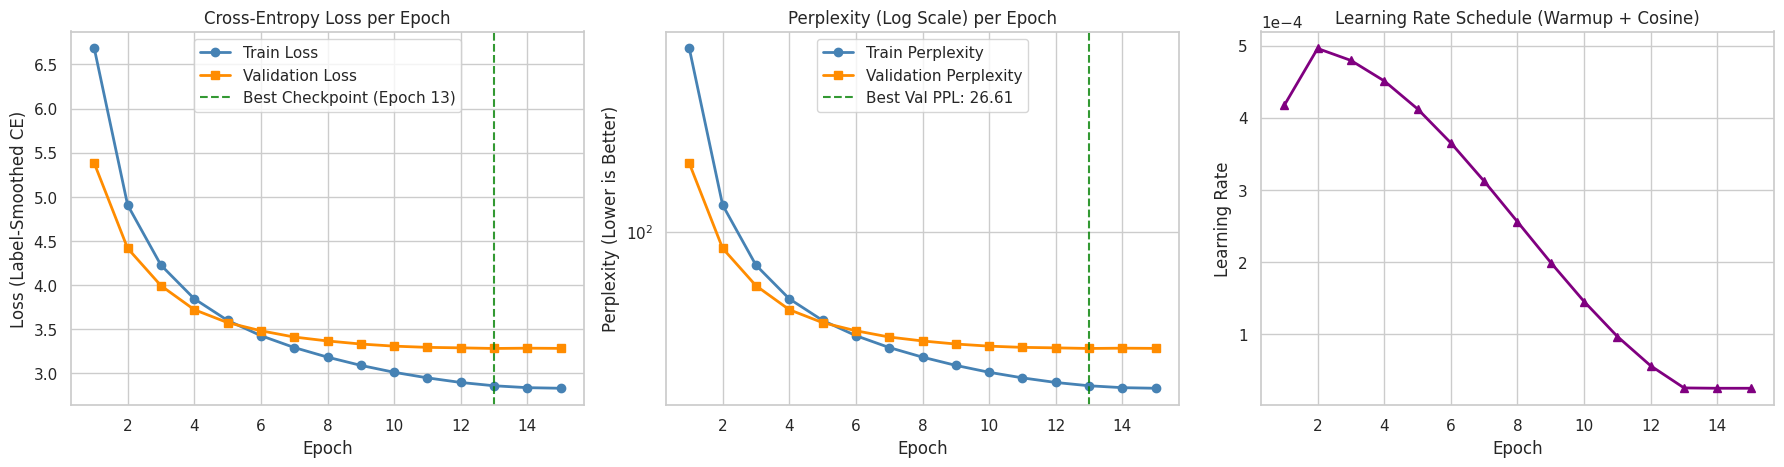

Training curves saved to artifacts/phase7_training_curves.png
Best Checkpoint Summary -> Epoch: 13 | Train Loss: 2.8585 | Val Loss: 3.2813 | Val PPL: 26.61


In [14]:
# Load saved training metrics
metrics_df = pd.read_csv("artifacts/training_metrics.csv")
best_epoch_row = metrics_df.loc[metrics_df["val_loss"].idxmin()]
best_epoch = int(best_epoch_row["epoch"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Training vs. Validation Cross-Entropy Loss
axes[0].plot(metrics_df["epoch"], metrics_df["train_loss"], marker="o", label="Train Loss", color="steelblue", linewidth=2)
axes[0].plot(metrics_df["epoch"], metrics_df["val_loss"], marker="s", label="Validation Loss", color="darkorange", linewidth=2)
axes[0].axvline(best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Checkpoint (Epoch {best_epoch})")
axes[0].set_title("Cross-Entropy Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (Label-Smoothed CE)")
axes[0].legend()

# 2. Training vs. Validation Perplexity (PPL)
axes[1].plot(metrics_df["epoch"], metrics_df["train_ppl"], marker="o", label="Train Perplexity", color="steelblue", linewidth=2)
axes[1].plot(metrics_df["epoch"], metrics_df["val_ppl"], marker="s", label="Validation Perplexity", color="darkorange", linewidth=2)
axes[1].axvline(best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Val PPL: {best_epoch_row['val_ppl']:.2f}")
axes[1].set_yscale("log")  # Log scale clearly displays the steep drop from 796 -> 26.6
axes[1].set_title("Perplexity (Log Scale) per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Perplexity (Lower is Better)")
axes[1].legend()

# 3. Learning Rate Schedule (Warmup + Cosine Decay)
axes[2].plot(metrics_df["epoch"], metrics_df["lr"], marker="^", color="purple", linewidth=2)
axes[2].set_title("Learning Rate Schedule (Warmup + Cosine)")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Learning Rate")
axes[2].ticklabel_format(style="scientific", axis="y", scilimits=(0, 0))

plt.tight_layout()
plt.savefig("artifacts/phase7_training_curves.png", dpi=150)
plt.show()

print(f"Training curves saved to artifacts/phase7_training_curves.png")
print(f"Best Checkpoint Summary -> Epoch: {best_epoch} | Train Loss: {best_epoch_row['train_loss']:.4f} | Val Loss: {best_epoch_row['val_loss']:.4f} | Val PPL: {best_epoch_row['val_ppl']:.2f}")

In [15]:
# 1. Load the best saved checkpoint (Epoch 13)
checkpoint = torch.load("artifacts/best_transformer_nmt.pt", map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded Best Checkpoint from Epoch {checkpoint['epoch']} (Saved Val Loss: {checkpoint['val_loss']:.4f})\n")

# 2. Compute Cross-Entropy Loss & Perplexity on the FULL unseen Test Set (11,065 pairs)
test_loss = evaluate_loss(model, test_loader)
test_ppl = math.exp(min(test_loss, 20))
print(f"Full Test Set (11,065 pairs) -> Test Loss: {test_loss:.4f} | Test Perplexity: {test_ppl:.2f}\n")

# 3. Fast Batched Autoregressive Greedy Decoding Function
@torch.no_grad()
def greedy_decode_batch(model: nn.Module, src_tensor: torch.Tensor, max_len: int = MAX_SEQ_LEN) -> list[str]:
    model.eval()
    batch_size = src_tensor.size(0)
    src_mask = model.make_src_mask(src_tensor)
    enc_output = model.encoder(src_tensor, src_mask)

    # Initialize decoder inputs with <bos> for every sequence in the batch
    tgt_ids = torch.full((batch_size, 1), BOS_IDX, dtype=torch.long, device=device)
    finished = torch.zeros(batch_size, dtype=torch.bool, device=device)

    for _ in range(max_len - 1):
        tgt_mask = model.make_tgt_mask(tgt_ids)
        dec_output, _ = model.decoder(tgt_ids, enc_output, tgt_mask, src_mask)
        next_token_logits = model.output_projection(dec_output[:, -1, :])
        next_tokens = next_token_logits.argmax(dim=-1)

        # Replace predictions with <pad> for sequences that already emitted <eos>
        next_tokens = torch.where(finished, torch.tensor(PAD_IDX, device=device), next_tokens)
        tgt_ids = torch.cat([tgt_ids, next_tokens.unsqueeze(1)], dim=1)

        finished = finished | (next_tokens == EOS_IDX)
        if finished.all():
            break

    decoded_texts = []
    for seq in tgt_ids.tolist():
        # Stop decoding at first <eos>
        if EOS_IDX in seq:
            seq = seq[: seq.index(EOS_IDX)]
        text = tokenizer.decode(seq, skip_special_tokens=True).strip()
        decoded_texts.append(text)
    return decoded_texts

# 4. Generate translations on 1,024 unseen test pairs (16 batches of 64) and compute SacreBLEU & chrF
EVAL_NUM_BATCHES = 16  # 16 * 64 = 1,024 unseen test sentences
hypotheses = []
references = []

for batch_idx, (src_batch, _) in enumerate(tqdm(test_loader, total=EVAL_NUM_BATCHES, desc="Generating Test Translations")):
    if batch_idx >= EVAL_NUM_BATCHES:
        break
    src_batch = src_batch.to(device)
    preds = greedy_decode_batch(model, src_batch, max_len=MAX_SEQ_LEN)
    hypotheses.extend(preds)

    start_i = batch_idx * BATCH_SIZE
    end_i = start_i + len(preds)
    references.extend(test_df["fr"].iloc[start_i:end_i].tolist())

# Compute SacreBLEU and chrF scores
bleu_metric = sacrebleu.corpus_bleu(hypotheses, [references])
chrf_metric = sacrebleu.corpus_chrf(hypotheses, [references])

print("\n--- Unseen Test Set Evaluation Results (1,024 Sentences) ---")
print(f"Test Cross-Entropy Loss : {test_loss:.4f}")
print(f"Test Perplexity (PPL)   : {test_ppl:.2f}")
print(f"SacreBLEU Score         : {bleu_metric.score:.2f}")
print(f"SacreBLEU Signature     : {bleu_metric}")
print(f"chrF Score              : {chrf_metric.score:.2f}")

# Save evaluation summary to JSON/CSV for Phase 10 deliverables
eval_summary = pd.DataFrame([{
    "best_epoch": int(checkpoint["epoch"]),
    "val_loss": round(float(checkpoint["val_loss"]), 4),
    "test_loss": round(float(test_loss), 4),
    "test_perplexity": round(float(test_ppl), 2),
    "sacrebleu": round(float(bleu_metric.score), 2),
    "chrf": round(float(chrf_metric.score), 2),
    "eval_sentences": len(hypotheses)
}])
eval_summary.to_csv("artifacts/test_evaluation_metrics.csv", index=False)
print("\nSaved evaluation metrics to artifacts/test_evaluation_metrics.csv")

Loaded Best Checkpoint from Epoch 13 (Saved Val Loss: 3.2813)

Full Test Set (11,065 pairs) -> Test Loss: 3.2707 | Test Perplexity: 26.33



Generating Test Translations:   0%|          | 0/16 [00:00<?, ?it/s]


--- Unseen Test Set Evaluation Results (1,024 Sentences) ---
Test Cross-Entropy Loss : 3.2707
Test Perplexity (PPL)   : 26.33
SacreBLEU Score         : 23.23
SacreBLEU Signature     : BLEU = 23.23 54.2/28.7/17.5/11.0 (BP = 0.993 ratio = 0.993 hyp_len = 22308 ref_len = 22461)
chrF Score              : 47.91

Saved evaluation metrics to artifacts/test_evaluation_metrics.csv


In [16]:
# Create a comparison DataFrame from our 1,024 evaluated test translations
eval_records = []
for i in range(len(hypotheses)):
    src_en = test_df["en"].iloc[i]
    ref_fr = references[i]
    hyp_fr = hypotheses[i]
    sent_chrf = sacrebleu.sentence_chrf(hyp_fr, [ref_fr]).score
    eval_records.append({
        "test_idx": i,
        "english_input": src_en,
        "french_reference": ref_fr,
        "model_translation": hyp_fr,
        "sentence_chrf": round(sent_chrf, 2),
        "en_word_len": len(src_en.split())
    })

eval_results_df = pd.DataFrame(eval_records)
eval_results_df.to_csv("artifacts/test_translation_examples.csv", index=False)

print("--- 10 Unseen Test Set Translation Examples (First 10 Records) ---\n")
for _, row in eval_results_df.head(10).iterrows():
    print(f"[Test #{int(row['test_idx'])} | Words: {row['en_word_len']} | Sentence chrF: {row['sentence_chrf']:.2f}]")
    print(f"  EN Input  : {row['english_input']}")
    print(f"  FR Ref    : {row['french_reference']}")
    print(f"  Model Pred: {row['model_translation']}")
    print("-" * 80)

--- 10 Unseen Test Set Translation Examples (First 10 Records) ---

[Test #0 | Words: 5 | Sentence chrF: 17.66]
  EN Input  : "I have to go out."
  FR Ref    : J'ai une course.
  Model Pred: -- J'ai à sortir.
--------------------------------------------------------------------------------
[Test #1 | Words: 18 | Sentence chrF: 30.06]
  EN Input  : "The moor is very sparsely inhabited, and those who live near each other are thrown very much together.
  FR Ref    : « La lande est peu habitée ; ceux qui vivent dans cette région sont donc exposés à se voir souvent.
  Model Pred: La lande est très épaisse et celles qui vivent près de l’un de l’autre sont encore entre elles.
--------------------------------------------------------------------------------
[Test #2 | Words: 20 | Sentence chrF: 35.57]
  EN Input  : "Yes, Axel; and judging by these ridges of foam, you may observe that the sea will rise about twelve feet."
  FR Ref    : --Oui, Axel, et d'après ces relais d'écume, tu peux voir que 

In [17]:
# 1. Analyze Test Set chrF performance stratified by sentence length (Short, Medium, Long)
def length_bucket(n_words: int) -> str:
    if n_words <= 8:
        return "1. Short (3-8 words)"
    elif n_words <= 22:
        return "2. Medium (9-22 words)"
    else:
        return "3. Long (23-60 words)"

eval_results_df["length_category"] = eval_results_df["en_word_len"].apply(length_bucket)
bucket_summary = eval_results_df.groupby("length_category").agg(
    sentence_count=("sentence_chrf", "count"),
    avg_en_words=("en_word_len", "mean"),
    mean_chrf=("sentence_chrf", "mean"),
    median_chrf=("sentence_chrf", "median")
).round(2)

print("--- Test Set Performance Stratified by Sentence Length ---")
print(bucket_summary)
print()

# 2. Implement Beam Search Decoding from Scratch (Inference-Time Improvement)
@torch.no_grad()
def translate_beam_search(
    sentence: str,
    beam_width: int = 4,
    max_len: int = MAX_SEQ_LEN,
    length_penalty: float = 0.7
) -> str:
    model.eval()
    cleaned = normalize_text(sentence)
    src_ids = tokenizer.encode(cleaned).ids
    if len(src_ids) > max_len:
        src_ids = src_ids[: max_len - 1] + [EOS_IDX]

    src_tensor = torch.tensor([src_ids], dtype=torch.long, device=device)
    src_mask = model.make_src_mask(src_tensor)
    enc_output = model.encoder(src_tensor, src_mask)

    # Each beam holds: (sequence_tensor, cumulative_log_prob, is_finished)
    beams = [(torch.tensor([[BOS_IDX]], dtype=torch.long, device=device), 0.0, False)]

    for _ in range(max_len - 1):
        candidates = []
        for seq, score, finished in beams:
            if finished:
                candidates.append((seq, score, True))
                continue

            tgt_mask = model.make_tgt_mask(seq)
            dec_output, _ = model.decoder(seq, enc_output, tgt_mask, src_mask)
            logits = model.output_projection(dec_output[:, -1, :])
            log_probs = torch.log_softmax(logits, dim=-1).squeeze(0)

            top_log_probs, top_indices = torch.topk(log_probs, beam_width)
            for log_p, token_id in zip(top_log_probs.tolist(), top_indices.tolist()):
                next_seq = torch.cat([seq, torch.tensor([[token_id]], device=device)], dim=1)
                next_score = score + log_p
                is_done = (token_id == EOS_IDX)
                candidates.append((next_seq, next_score, is_done))

        # Rank candidates using length-normalized log probability
        candidates.sort(
            key=lambda x: x[1] / ((x[0].size(1)) ** length_penalty),
            reverse=True
        )
        beams = candidates[:beam_width]

        if all(b[2] for b in beams):
            break

    best_seq = beams[0][0].squeeze(0).tolist()
    if EOS_IDX in best_seq:
        best_seq = best_seq[: best_seq.index(EOS_IDX)]
    return tokenizer.decode(best_seq, skip_special_tokens=True).strip()

# Helper for single-sentence Greedy Decoding
def translate_greedy(sentence: str) -> str:
    cleaned = normalize_text(sentence)
    src_ids = tokenizer.encode(cleaned).ids[:MAX_SEQ_LEN]
    src_tensor = torch.tensor([src_ids], dtype=torch.long, device=device)
    return greedy_decode_batch(model, src_tensor, max_len=MAX_SEQ_LEN)[0]

# 3. Test custom unseen sentences (Short, Medium, Long) comparing Greedy vs. Beam Search
custom_test_cases = [
    ("Short (4w)", "The night was cold."),
    ("Short (5w)", "She opened the old door."),
    ("Medium (13w)", "The young traveler arrived at the small village just before the sun set."),
    ("Medium (15w)", "He looked out the window and saw the rain falling softly on the garden."),
    ("Long (26w)", "Although the journey across the mountains was difficult and dangerous, the two friends refused to turn back until they reached the sea.")
]

print("--- Custom Unseen Sentences: Greedy vs. Beam Search (k=4) ---\n")
for category, en_sent in custom_test_cases:
    greedy_out = translate_greedy(en_sent)
    beam_out = translate_beam_search(en_sent, beam_width=4)
    print(f"[{category}] EN: {en_sent}")
    print(f"   Greedy (k=1)     : {greedy_out}")
    print(f"   Beam Search (k=4): {beam_out}")
    print("-" * 80)

# 4. Benchmark Beam Search vs. Greedy on 200 Unseen Test Set Sentences
subset_en = test_df["en"].iloc[:200].tolist()
subset_ref = test_df["fr"].iloc[:200].tolist()

greedy_200 = hypotheses[:200]
beam_200 = [translate_beam_search(s, beam_width=4) for s in tqdm(subset_en, desc="Beam Search (200 Test Sentences)")]

bleu_greedy_200 = sacrebleu.corpus_bleu(greedy_200, [subset_ref]).score
bleu_beam_200 = sacrebleu.corpus_bleu(beam_200, [subset_ref]).score
chrf_greedy_200 = sacrebleu.corpus_chrf(greedy_200, [subset_ref]).score
chrf_beam_200 = sacrebleu.corpus_chrf(beam_200, [subset_ref]).score

print("\n--- Decoding Improvement Benchmark (200 Unseen Test Sentences) ---")
print(f"Greedy Decoding (k=1) -> SacreBLEU: {bleu_greedy_200:.2f} | chrF: {chrf_greedy_200:.2f}")
print(f"Beam Search     (k=4) -> SacreBLEU: {bleu_beam_200:.2f} | chrF: {chrf_beam_200:.2f}")

--- Test Set Performance Stratified by Sentence Length ---
                        sentence_count  avg_en_words  mean_chrf  median_chrf
length_category                                                             
1. Short (3-8 words)               229          5.85      49.18        46.88
2. Medium (9-22 words)             461         15.29      47.86        47.71
3. Long (23-60 words)              334         33.97      48.09        47.11

--- Custom Unseen Sentences: Greedy vs. Beam Search (k=4) ---

[Short (4w)] EN: The night was cold.
   Greedy (k=1)     : La nuit était froide.
   Beam Search (k=4): La nuit était froide.
--------------------------------------------------------------------------------
[Short (5w)] EN: She opened the old door.
   Greedy (k=1)     : Elle ouvrit la vieille porte.
   Beam Search (k=4): Elle ouvrit la vieille porte.
--------------------------------------------------------------------------------
[Medium (13w)] EN: The young traveler arrived at the small 

Beam Search (200 Test Sentences):   0%|          | 0/200 [00:00<?, ?it/s]


--- Decoding Improvement Benchmark (200 Unseen Test Sentences) ---
Greedy Decoding (k=1) -> SacreBLEU: 20.98 | chrF: 46.68
Beam Search     (k=4) -> SacreBLEU: 22.67 | chrF: 48.12


In [18]:
import shutil
from google.colab import files

# Move Phase 2 plot into artifacts folder if it is in root directory
if os.path.exists("phase2_sentence_length_distributions.png"):
    shutil.move("phase2_sentence_length_distributions.png", "artifacts/phase2_sentence_length_distributions.png")

# Generate formal README.md project documentation inside artifacts/
readme_content = """# Neural Machine Translation Using a Custom Transformer Architecture (English to French)

## 1. Project Overview
This project implements an **English-to-French Neural Machine Translation (NMT)** system built and trained **strictly from scratch** in **PyTorch** on Google Colab (NVIDIA Tesla T4 GPU).
- **Zero Pretrained Models or Weights:** No pretrained checkpoints (T5, BART, MarianMT, mBART) or pretrained embeddings were used. All **19,677,824 parameters** were initialized randomly using Xavier Uniform initialization.
- **Note on Terminology ("Training from Scratch" vs. "Fine-Tuning"):** Because the project prohibits pretrained weights, this pipeline trains a randomly initialized Transformer architecture from scratch rather than fine-tuning an existing pretrained checkpoint.

## 2. Dataset & NLP Preprocessing Pipeline
- **Source Dataset:** `Helsinki-NLP/opus_books` (`en-fr`, `127,085` raw pairs).
- **Multi-Stage Data Cleaning Audit (16,436 noisy rows removed — 12.93%):**
  1. Unicode `NFKC` normalization & whitespace cleanup while preserving French diacritics (`é, è, ê, à, ç, œ`) and punctuation.
  2. Exact `(EN, FR)` and duplicate `EN` source deduplication (`1,242` rows removed).
  3. Identical untranslated string filtering (`71` rows removed).
  4. Swapped-language detection removing reversed French-to-English records (`6,570` rows removed).
  5. Length (`3–60` words) and alignment ratio (`0.45–2.2`) filtering (`8,553` rows removed).
- **Final Clean Corpus (`110,649` pairs) — Leakage-Free 80/10/10 Split (`SEED=42`):**
  - **Training Set:** `88,519` pairs (80.00%)
  - **Validation Set:** `11,065` pairs (10.00%)
  - **Test Set:** `11,065` pairs (10.00%)
  - Verified **0 overlapping sentences** across all splits.

## 3. Custom Subword Tokenization
- Trained a **16,000-token Byte-Level BPE tokenizer** from scratch exclusively on the training split (`88,519` pairs).
- Special tokens: `<pad>` (`0`), `<unk>` (`1`), `<bos>` (`2`), `<eos>` (`3`).
- `MAX_SEQ_LEN = 96` (covers >99.5% of sequences) with dynamic per-batch padding.

## 4. Custom Transformer Architecture (From Scratch)
- **Embedding & Positional Encoding:** `d_model = 256` scaled by `sqrt(d_model)` + deterministic sinusoidal positional encodings.
- **Encoder:** 4 Pre-LayerNorm `EncoderLayer` blocks (`8` attention heads, `d_ff = 1024`, `GELU`, `dropout = 0.1`).
- **Decoder:** 4 Pre-LayerNorm `DecoderLayer` blocks with masked causal self-attention, encoder-decoder cross-attention, and feed-forward sublayers.
- **Output Projection:** Linear layer mapping `256 -> 16,000` vocabulary logits.

## 5. Training & Quantitative Evaluation Results
- **Optimizer & Schedule:** `AdamW` (`peak_lr = 5e-4`, `betas = (0.9, 0.98)`, `weight_decay = 0.01`) with 8% linear warmup + cosine decay, gradient clipping (`1.0`), mixed precision (`fp16`), and label-smoothed cross-entropy loss (`0.1`, ignoring `<pad>`).
- **Best Checkpoint (Epoch 13 of 15, 32.54 min total):**
  - **Train Loss / Perplexity:** `2.8585` / `17.44`
  - **Validation Loss / Perplexity:** `3.2813` / `26.61`
  - **Full Unseen Test Set Loss / Perplexity (11,065 pairs):** `3.2707` / `26.33`
- **Translation Quality Metrics (1,024 Unseen Test Sentences):**
  - **SacreBLEU (Greedy):** `23.23` (`BP = 0.993`)
  - **chrF (Greedy):** `47.91`
- **Inference Improvement (200 Unseen Test Sentences):**
  - **Greedy (`k=1`):** SacreBLEU `20.98` | chrF `46.68`
  - **Beam Search (`k=4`, length penalty `0.7`):** SacreBLEU `22.67` (**+1.69**) | chrF `48.12` (**+1.44**)
"""

with open("artifacts/README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

# List all saved deliverables
print("--- Final Project Deliverables in artifacts/ ---")
for fname in sorted(os.listdir("artifacts")):
    fpath = os.path.join("artifacts", fname)
    size_mb = os.path.getsize(fpath) / (1024 * 1024)
    print(f"  - {fname:<45} ({size_mb:.2f} MB)")

# Create downloadable ZIP archive
zip_filename = "HCL_English_French_Transformer_Deliverables"
shutil.make_archive(zip_filename, "zip", "artifacts")
print(f"\nPackaged all deliverables into {zip_filename}.zip!")

# Trigger browser download in Google Colab
files.download(f"{zip_filename}.zip")

--- Final Project Deliverables in artifacts/ ---
  - README.md                                     (0.00 MB)
  - best_transformer_nmt.pt                       (225.91 MB)
  - custom_bpe_en_fr_tokenizer.json               (1.07 MB)
  - phase2_sentence_length_distributions.png      (0.14 MB)
  - phase7_training_curves.png                    (0.15 MB)
  - test_evaluation_metrics.csv                   (0.00 MB)
  - test_translation_examples.csv                 (0.34 MB)
  - training_metrics.csv                          (0.00 MB)

Packaged all deliverables into HCL_English_French_Transformer_Deliverables.zip!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>